# 04 · Preparación del dataset: split temporal, purga y folds

> **Flujo del proyecto** (diagrama del profesor)
> `01 Limpieza` → `02 Exploración` → `03 Creación de variables` → `04 Preparación (split temporal + folds)` →
> `05a Logística` · `05b Random Forest` · `05c XGBoost` · `05d Red neuronal` (cada uno: selección de variables → hiperparámetros) →
> `06 Selección del mejor modelo y prueba final en test`


    **Entrada:** `dataset_pedidos.parquet` · **Salida:** `X_train`, `X_test`, metadatos y `folds.json` en `datos/processed/`.

    ```
    |------------------ TRAIN (2017-01 → 2018-04) ------------------|~purga~|---- TEST (2018-05 → 2018-08) ----|
    | fold 1: tr | va |                                              |
    | fold 2: tr      | va |                                         |      sólo se abre UNA vez,
    |   ...                                                          |      en el notebook 06
    | fold 5: tr                                   | va |            |
    ```

    - **Test aparte:** el bloque más reciente. No participa en ninguna decisión.
    - **K-Fold temporal (5 folds, ventana creciente):** se entrena con el pasado y se valida con el bloque siguiente.
    - **Purga:** un pedido sólo entrena si su label ya se conocía al inicio de la validación/test. Sin esto, los últimos pedidos
      del entrenamiento tendrían labels que en la vida real todavía no se sabrían (fuga sutil que el `TimeSeriesSplit` normal no evita).
    - **One-hot** ajustado sólo con train (20 categorías más frecuentes por variable; el resto → `infrequent`).

In [1]:
import sys, json, time, warnings
from pathlib import Path

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src import config, viz
viz.aplicar_estilo()
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

import joblib
from src import splits as S, preprocesamiento as P

In [2]:
df = pd.read_parquet(config.DATOS_PROCESSED / "dataset_pedidos.parquet")
idx_train, idx_test, purgados = S.corte_test(df, config.FECHA_CORTE_TEST)
df_train = df.iloc[idx_train].reset_index(drop=True)
df_test = df.iloc[idx_test].reset_index(drop=True)

def fila(d):
    return {"Filas": len(d), "Desde": d["order_purchase_timestamp"].min().date(),
            "Hasta": d["order_purchase_timestamp"].max().date(), "% tardíos": round(d["delivery_late"].mean() * 100, 2)}
resumen = pd.DataFrame({"Train": fila(df_train), "Test": fila(df_test)}).T
display(resumen)
print(f"Pedidos purgados entre train y test (label conocido después del {config.FECHA_CORTE_TEST}): {purgados:,}")

,Filas,Desde,Hasta,% tardíos
Train,68287,2017-01-05,2018-04-27,7.59
Test,25350,2018-05-01,2018-08-29,4.4


Pedidos purgados entre train y test (label conocido después del 2018-05-01): 2,564


In [3]:
enc = P.ajustar_codificador(df_train)
X_train, X_test = P.construir_X(df_train, enc), P.construir_X(df_test, enc)
y_train, y_test = df_train["delivery_late"].reset_index(drop=True), df_test["delivery_late"].reset_index(drop=True)
assert list(X_train.columns) == list(X_test.columns)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
for col, cats in zip(P.COLUMNAS_CATEGORICAS, enc.categories_):
    print(f"  {col:20s} {len(cats):3d} categorías en train")

X_train: (68287, 105) | X_test: (25350, 105)
  customer_state        27 categorías en train
  seller_state          22 categorías en train
  main_payment_type      4 categorías en train
  main_category         73 categorías en train
  purchase_weekday       7 categorías en train
  franja_horaria         4 categorías en train


### K-Fold temporal con purga

In [4]:
folds = S.folds_temporales(df_train["order_purchase_timestamp"], df_train["label_conocida_en"], config.N_FOLDS)
S.verificar_sin_fuga(folds, df_train["order_purchase_timestamp"], df_train["label_conocida_en"])
tabla_folds = S.resumen_folds(folds, df_train["order_purchase_timestamp"], y_train)
display(tabla_folds)
print("✓ Ningún label de entrenamiento se conocía después del inicio de su validación.")

,Train desde,Train hasta,Filas train,Val desde,Val hasta,Filas val,% tardíos train,% tardíos val
Fold,,,,,,,,
1,2017-01-05,2017-06-04,10167,2017-06-06,2017-09-06,11381,3.84,2.93
2,2017-01-05,2017-09-05,21236,2017-09-06,2017-11-22,11381,3.23,5.32
3,2017-01-05,2017-11-19,31841,2017-11-22,2018-01-10,11381,3.51,9.96
4,2017-01-05,2018-01-09,43040,2018-01-10,2018-02-28,11381,5.33,10.74
5,2017-01-05,2018-02-26,53307,2018-02-28,2018-04-27,11381,5.33,12.56


✓ Ningún label de entrenamiento se conocía después del inicio de su validación.


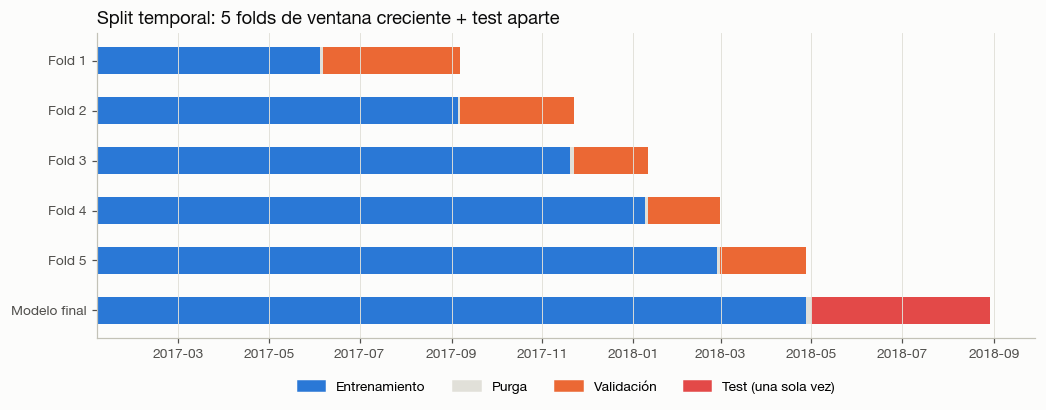

In [5]:
import matplotlib.dates as mdates
from matplotlib.patches import Patch
fechas = df_train["order_purchase_timestamp"]
fig, ax = plt.subplots(figsize=(11, 3.6))
def tramo(y_pos, a, b, color):
    ax.barh(y_pos, mdates.date2num(b) - mdates.date2num(a), left=mdates.date2num(a), color=color, height=0.55)
for k, (tr, va) in enumerate(folds, 1):
    y_pos = config.N_FOLDS + 1 - k
    tramo(y_pos, fechas.iloc[tr[0]], fechas.iloc[tr[-1]], viz.A_TIEMPO)
    tramo(y_pos, fechas.iloc[tr[-1]], fechas.iloc[va[0]], viz.GRID)
    tramo(y_pos, fechas.iloc[va[0]], fechas.iloc[va[-1]], "#eb6834")
ini_te, fin_te = df_test["order_purchase_timestamp"].min(), df_test["order_purchase_timestamp"].max()
fin_tr = fechas.max()
tramo(0, fechas.iloc[0], fin_tr, viz.A_TIEMPO)
tramo(0, fin_tr, ini_te, viz.GRID)
tramo(0, ini_te, fin_te, viz.TARDIO)
ax.xaxis_date()
ax.set_yticks(range(config.N_FOLDS + 1), ["Modelo final"] + [f"Fold {k}" for k in range(config.N_FOLDS, 0, -1)])
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=viz.A_TIEMPO, label="Entrenamiento"), Patch(color=viz.GRID, label="Purga"),
                   Patch(color="#eb6834", label="Validación"), Patch(color=viz.TARDIO, label="Test (una sola vez)")],
          ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.set_title("Split temporal: 5 folds de ventana creciente + test aparte")
viz.guardar(fig, "split_temporal"); plt.show()

### Correlación con la variable objetivo (sólo train)
Primera mirada a qué variables se relacionan con el retraso. La selección formal se hace por modelo con RFECV (05).

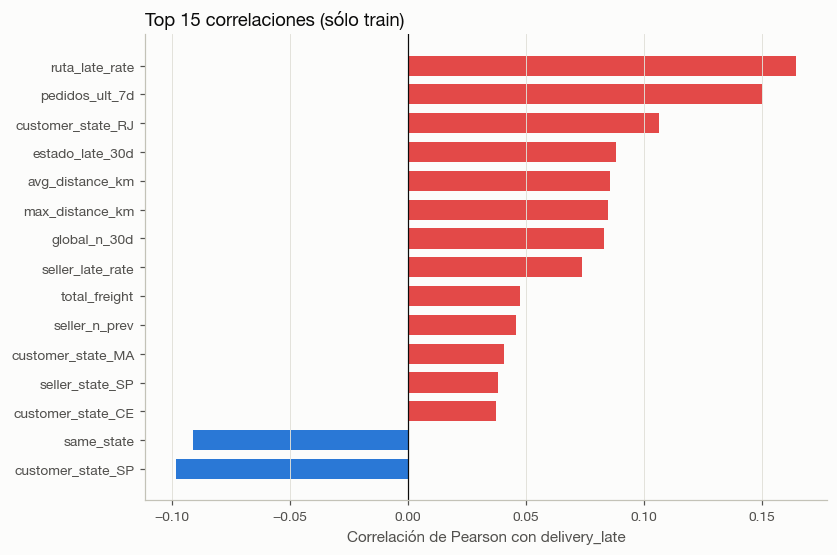

In [6]:
corr = X_train.assign(delivery_late=y_train).corr(numeric_only=True)["delivery_late"].drop("delivery_late").dropna()
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(15).sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top.values, color=np.where(top > 0, viz.TARDIO, viz.A_TIEMPO), height=0.7)
ax.axvline(0, color=viz.TINTA, linewidth=0.8); ax.grid(axis="y", visible=False)
ax.set_xlabel("Correlación de Pearson con delivery_late"); ax.set_title("Top 15 correlaciones (sólo train)")
viz.guardar(fig, "correlaciones_train"); plt.show()

In [7]:
X_train.to_parquet(config.DATOS_PROCESSED / "X_train.parquet", index=False)
X_test.to_parquet(config.DATOS_PROCESSED / "X_test.parquet", index=False)
meta_cols = ["order_id", "order_purchase_timestamp", "label_conocida_en", "delivery_late"]
df_train[meta_cols].to_parquet(config.DATOS_PROCESSED / "meta_train.parquet", index=False)
df_test[meta_cols].to_parquet(config.DATOS_PROCESSED / "meta_test.parquet", index=False)
(config.DATOS_PROCESSED / "folds.json").write_text(json.dumps([{"train": tr.tolist(), "val": va.tolist()} for tr, va in folds]))
joblib.dump(enc, config.DATOS_PROCESSED / "codificador_onehot.joblib")

split = {"train": {k: str(v) for k, v in fila(df_train).items()}, "test": {k: str(v) for k, v in fila(df_test).items()},
         "purgados": purgados, "n_variables": X_train.shape[1], "fecha_corte": config.FECHA_CORTE_TEST,
         "folds": json.loads(tabla_folds.reset_index().to_json(orient="records", date_format="iso"))}
(config.METRICAS / "split.json").write_text(json.dumps(split, indent=2, ensure_ascii=False))
print("Guardado en", config.DATOS_PROCESSED)

Guardado en /Users/fabiolajrz/Documents/proyecto_final_equipo_3/datos/processed
